# Rotterdam ER-interaction results analysis

This notebook analyzes the outputs from `results_er_interaction/aggregated/`.

It includes:

- predictive performance metrics: IBS, mean time-dependent AUC, C-index, mean Brier score;
- time-dependent AUC and Brier curves;
- treatment-effect estimates and confidence intervals;
- a slide-style ER-interaction table with rows for Hormonal/Chemo × Low/High ER and columns for FLEXI-Haz, Zhong et al., and Cox.

Expected input folder:

```text
results_er_interaction/
    aggregated/
        summary_by_model.csv
        summary_by_fold.csv
        auc_by_time.csv
        auc_by_time_summary.csv
        brier_by_time.csv
        brier_by_time_summary.csv
        treatment_effects_by_fold.csv
        treatment_effects_summary.csv
```

If the aggregated files are missing, first run:

```bash
python aggregate_rotterdam_results.py --results-dir results_er_interaction
```


In [17]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)
warnings.filterwarnings("ignore", category=RuntimeWarning)

# ---------------------------------------------------------------------
# Configuration
# ---------------------------------------------------------------------
# Put this notebook inside rotterdam_experiment/ and keep this default.
# If you run the notebook from another directory, change RESULTS_DIR manually.
CANDIDATE_RESULTS_DIRS = [
    Path("results_er_interaction"),
    Path("rotterdam_experiment/results_er_interaction"),
    Path.cwd() / "results_er_interaction",
]

RESULTS_DIR = next((p for p in CANDIDATE_RESULTS_DIRS if p.exists()), Path("results_er_interaction"))
AGG_DIR = RESULTS_DIR / "aggregated"
OUT_DIR = RESULTS_DIR / "analysis_outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("Working directory:", Path.cwd())
print("Results directory:", RESULTS_DIR.resolve())
print("Aggregated directory:", AGG_DIR.resolve())
print("Analysis outputs:", OUT_DIR.resolve())


Working directory: /Users/matanbartuv/BSc/Survival_Analysis_Research_Program/flexihaz_package/simulations/rotterdam_experiment
Results directory: /Users/matanbartuv/BSc/Survival_Analysis_Research_Program/flexihaz_package/simulations/rotterdam_experiment/results_er_interaction
Aggregated directory: /Users/matanbartuv/BSc/Survival_Analysis_Research_Program/flexihaz_package/simulations/rotterdam_experiment/results_er_interaction/aggregated
Analysis outputs: /Users/matanbartuv/BSc/Survival_Analysis_Research_Program/flexihaz_package/simulations/rotterdam_experiment/results_er_interaction/analysis_outputs


In [18]:
def read_csv_optional(path: Path) -> pd.DataFrame:
    if not path.exists():
        print(f"Missing file: {path}")
        return pd.DataFrame()
    df = pd.read_csv(path)
    print(f"Loaded {path.name}: shape={df.shape}")
    return df

summary_by_model = read_csv_optional(AGG_DIR / "summary_by_model.csv")
summary_by_fold = read_csv_optional(AGG_DIR / "summary_by_fold.csv")
auc_by_time = read_csv_optional(AGG_DIR / "auc_by_time.csv")
auc_by_time_summary = read_csv_optional(AGG_DIR / "auc_by_time_summary.csv")
brier_by_time = read_csv_optional(AGG_DIR / "brier_by_time.csv")
brier_by_time_summary = read_csv_optional(AGG_DIR / "brier_by_time_summary.csv")
treatment_by_fold = read_csv_optional(AGG_DIR / "treatment_effects_by_fold.csv")
treatment_summary = read_csv_optional(AGG_DIR / "treatment_effects_summary.csv")

if summary_by_model.empty and treatment_summary.empty:
    raise FileNotFoundError(
        f"No aggregated result files were found in {AGG_DIR}. "
        "Run: python aggregate_rotterdam_results.py --results-dir results_er_interaction"
    )


Loaded summary_by_model.csv: shape=(5, 42)
Loaded summary_by_fold.csv: shape=(21, 82)
Loaded auc_by_time.csv: shape=(2940, 5)
Loaded auc_by_time_summary.csv: shape=(700, 7)
Loaded brier_by_time.csv: shape=(2940, 5)
Loaded brier_by_time_summary.csv: shape=(700, 7)
Loaded treatment_effects_by_fold.csv: shape=(44, 15)
Loaded treatment_effects_summary.csv: shape=(12, 42)


## Display labels and helper functions

In [19]:
MODEL_LABELS = {
    "flexihaz_partial_linear": "FLEXI-Haz",
    "zhong2022_ph": "Zhong et al.",
    "cox_ph": "Cox",
    "flexihaz_nonlinear": "FLEXI-Haz nonlinear",
    "random_survival_forest": "RSF",
    "zhong_mueller_wang_placeholder": "Zhong placeholder",
}

MODEL_ORDER = [
    "flexihaz_partial_linear",
    "zhong2022_ph",
    "cox_ph",
    "flexihaz_nonlinear",
    "random_survival_forest",
]

TREATMENT_LABELS = {
    "hormon_low_er": ("Hormonal", "Low"),
    "hormon_high_er": ("Hormonal", "High"),
    "chemo_low_er": ("Chemo", "Low"),
    "chemo_high_er": ("Chemo", "High"),
    # Fallback names for the standard design, if the notebook is accidentally run on standard results.
    "hormon": ("Hormonal", "All"),
    "chemo": ("Chemo", "All"),
}

TREATMENT_ORDER = ["hormon_low_er", "hormon_high_er", "chemo_low_er", "chemo_high_er"]


def add_model_label(df: pd.DataFrame, model_col: str = "model") -> pd.DataFrame:
    out = df.copy()
    if model_col in out.columns:
        out["model_label"] = out[model_col].map(MODEL_LABELS).fillna(out[model_col].astype(str))
        out["model_order"] = out[model_col].map({m: i for i, m in enumerate(MODEL_ORDER)}).fillna(999).astype(int)
    return out


def round_table(df: pd.DataFrame, digits: int = 3) -> pd.DataFrame:
    out = df.copy()
    num_cols = out.select_dtypes(include=[np.number]).columns
    out[num_cols] = out[num_cols].round(digits)
    return out


def ci_cell(row: pd.Series) -> str:
    est = row.get("estimate_mean", np.nan)
    lo = row.get("ci95_low_mean", np.nan)
    hi = row.get("ci95_high_mean", np.nan)
    if pd.isna(est):
        return ""
    if pd.isna(lo) or pd.isna(hi):
        return f"{est:.3f}"
    return f"{est:.3f} ({lo:.3f}, {hi:.3f})"


def is_significant(row: pd.Series) -> bool:
    lo = row.get("ci95_low_mean", np.nan)
    hi = row.get("ci95_high_mean", np.nan)
    if pd.isna(lo) or pd.isna(hi):
        return False
    return (lo > 0) or (hi < 0)


## Predictive performance summary

The main predictive metrics are read from `summary_by_model.csv`.

Interpretation:

- `ibs_mean`: lower is better;
- `mean_auc_mean`: higher is better;
- `c_index_mean`: higher is better;
- `mean_brier_score_mean`: lower is better.


In [20]:
if summary_by_model.empty:
    display(Markdown("**No `summary_by_model.csv` found.**"))
else:
    perf = add_model_label(summary_by_model)
    keep_cols = [
        "model_label",
        "ibs_mean", "ibs_std",
        "mean_auc_mean", "mean_auc_std",
        "c_index_mean", "c_index_std",
        "mean_brier_score_mean", "mean_brier_score_std",
        "training_time_sec_mean", "prediction_time_sec_mean",
        "success",
    ]
    keep_cols = [c for c in keep_cols if c in perf.columns]
    perf_table = perf.sort_values("model_order")[keep_cols]
    display(round_table(perf_table, 4))
    perf_table.to_csv(OUT_DIR / "predictive_performance_summary.csv", index=False)


,model_label,ibs_mean,ibs_std,mean_auc_mean,mean_auc_std,c_index_mean,c_index_std,mean_brier_score_mean,mean_brier_score_std,training_time_sec_mean,prediction_time_sec_mean,success
2,FLEXI-Haz,0.1959,0.0103,0.7258,0.0227,0.6574,0.0140,0.1956,0.0104,44.6852,0.0598,5
4,Zhong et al.,0.2141,0.0182,0.6122,0.1026,0.5825,0.0757,0.2138,0.0186,22.8704,0.1733,5
0,Cox,0.1861,NaN,0.7181,NaN,0.6680,NaN,0.1854,NaN,0.0906,0.0127,1
1,FLEXI-Haz nonlinear,0.2013,0.0132,0.7151,0.0153,0.6559,0.0073,0.2011,0.0138,34.1429,0.0635,5
3,RSF,0.1922,0.0091,0.7308,0.0194,0.6604,0.0057,0.1919,0.0093,4.4138,0.5710,5


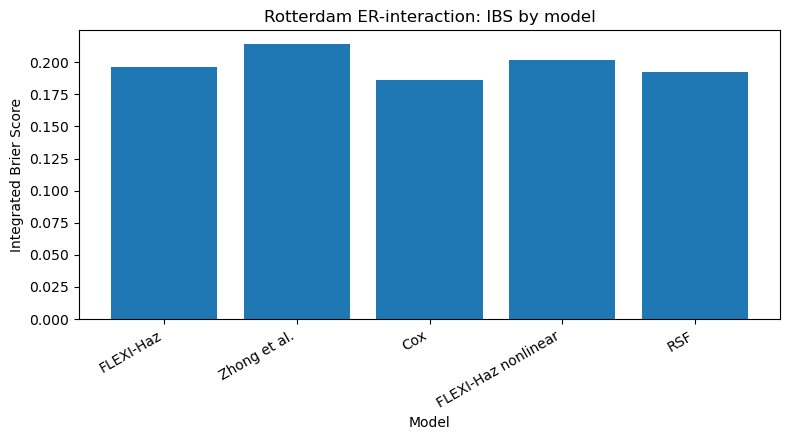

In [21]:
# Plot IBS by model, if available.
if not summary_by_model.empty and "ibs_mean" in summary_by_model.columns:
    plot_df = add_model_label(summary_by_model).sort_values("model_order")
    plot_df = plot_df.dropna(subset=["ibs_mean"])
    if not plot_df.empty:
        plt.figure(figsize=(8, 4.5))
        plt.bar(plot_df["model_label"], plot_df["ibs_mean"])
        plt.ylabel("Integrated Brier Score")
        plt.xlabel("Model")
        plt.title("Rotterdam ER-interaction: IBS by model")
        plt.xticks(rotation=30, ha="right")
        plt.tight_layout()
        plt.savefig(OUT_DIR / "ibs_by_model.png", dpi=200)
        plt.show()


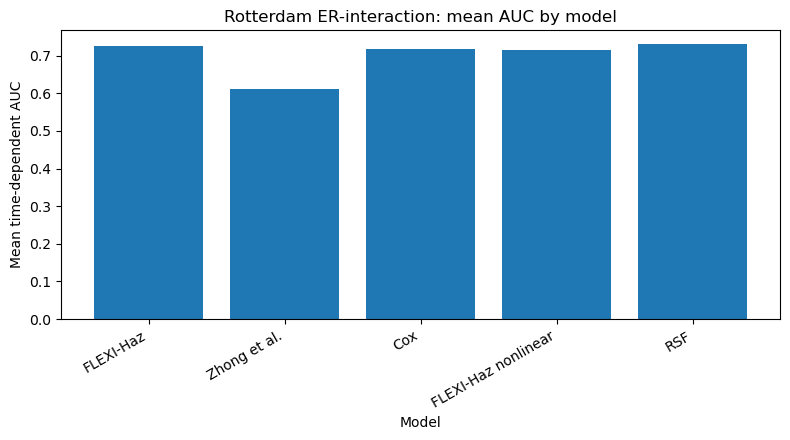

In [22]:
# Plot mean time-dependent AUC by model, if available.
if not summary_by_model.empty and "mean_auc_mean" in summary_by_model.columns:
    plot_df = add_model_label(summary_by_model).sort_values("model_order")
    plot_df = plot_df.dropna(subset=["mean_auc_mean"])
    if not plot_df.empty:
        plt.figure(figsize=(8, 4.5))
        plt.bar(plot_df["model_label"], plot_df["mean_auc_mean"])
        plt.ylabel("Mean time-dependent AUC")
        plt.xlabel("Model")
        plt.title("Rotterdam ER-interaction: mean AUC by model")
        plt.xticks(rotation=30, ha="right")
        plt.tight_layout()
        plt.savefig(OUT_DIR / "mean_auc_by_model.png", dpi=200)
        plt.show()


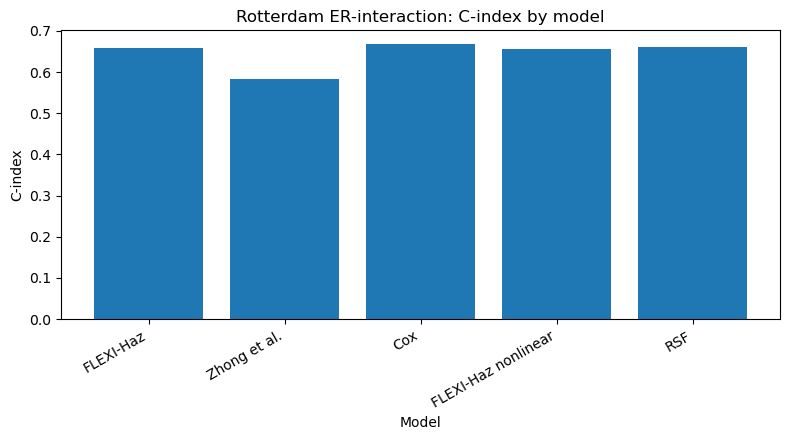

In [23]:
# Plot C-index by model, if available.
if not summary_by_model.empty and "c_index_mean" in summary_by_model.columns:
    plot_df = add_model_label(summary_by_model).sort_values("model_order")
    plot_df = plot_df.dropna(subset=["c_index_mean"])
    if not plot_df.empty:
        plt.figure(figsize=(8, 4.5))
        plt.bar(plot_df["model_label"], plot_df["c_index_mean"])
        plt.ylabel("C-index")
        plt.xlabel("Model")
        plt.title("Rotterdam ER-interaction: C-index by model")
        plt.xticks(rotation=30, ha="right")
        plt.tight_layout()
        plt.savefig(OUT_DIR / "c_index_by_model.png", dpi=200)
        plt.show()


## Time-dependent AUC and Brier curves

,model,time,auc_mean,auc_std,auc_min,auc_max,auc_count,model_label,model_order
280,flexihaz_partial_linear,50.0,0.5246,0.1747,0.4010,0.6481,2,FLEXI-Haz,0
281,flexihaz_partial_linear,100.0,0.7622,0.0477,0.7144,0.8269,5,FLEXI-Haz,0
282,flexihaz_partial_linear,150.0,0.7792,0.0586,0.7146,0.8465,5,FLEXI-Haz,0
283,flexihaz_partial_linear,200.0,0.7758,0.0446,0.7308,0.8242,5,FLEXI-Haz,0
284,flexihaz_partial_linear,250.0,0.7674,0.0523,0.6816,0.8200,5,FLEXI-Haz,0
285,flexihaz_partial_linear,300.0,0.7670,0.0390,0.7087,0.8098,5,FLEXI-Haz,0
286,flexihaz_partial_linear,350.0,0.7486,0.0287,0.7111,0.7899,5,FLEXI-Haz,0
287,flexihaz_partial_linear,400.0,0.7482,0.0245,0.7212,0.7861,5,FLEXI-Haz,0
288,flexihaz_partial_linear,450.0,0.7447,0.0205,0.7222,0.7779,5,FLEXI-Haz,0
289,flexihaz_partial_linear,500.0,0.7403,0.0254,0.7020,0.7634,5,FLEXI-Haz,0


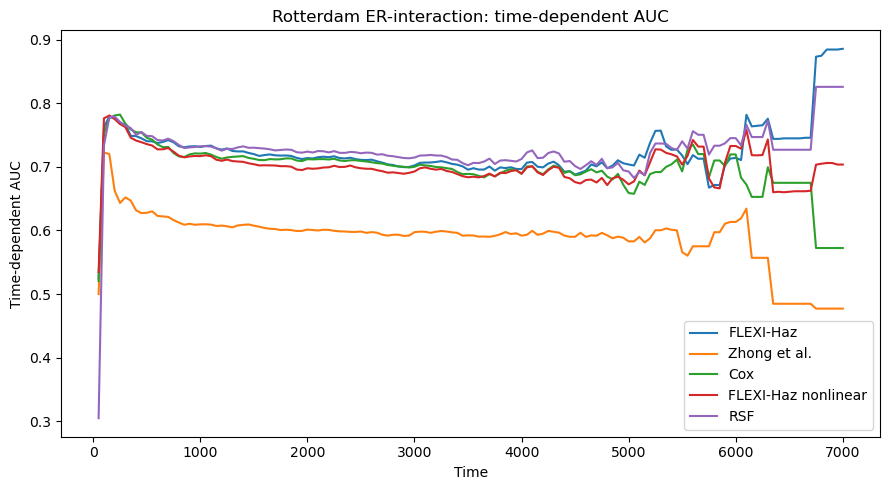

In [24]:
# Time-dependent AUC curves using aggregated mean over folds.
if auc_by_time_summary.empty:
    display(Markdown("**No `auc_by_time_summary.csv` found.**"))
else:
    auc_plot = add_model_label(auc_by_time_summary)
    auc_plot = auc_plot.dropna(subset=["time", "auc_mean"])
    display(round_table(auc_plot.sort_values(["model_order", "time"]).head(20), 4))
    if not auc_plot.empty:
        plt.figure(figsize=(9, 5))
        for model in MODEL_ORDER:
            tmp = auc_plot[auc_plot["model"] == model].sort_values("time")
            if tmp.empty:
                continue
            plt.plot(tmp["time"], tmp["auc_mean"], label=MODEL_LABELS.get(model, model))
        plt.xlabel("Time")
        plt.ylabel("Time-dependent AUC")
        plt.title("Rotterdam ER-interaction: time-dependent AUC")
        plt.legend()
        plt.tight_layout()
        plt.savefig(OUT_DIR / "auc_by_time.png", dpi=200)
        plt.show()


,model,time,brier_score_mean,brier_score_std,brier_score_min,brier_score_max,brier_score_count,model_label,model_order
280,flexihaz_partial_linear,50.0,0.0039,0.0023,0.0022,0.0055,2,FLEXI-Haz,0
281,flexihaz_partial_linear,100.0,0.0094,0.0038,0.0061,0.0145,5,FLEXI-Haz,0
282,flexihaz_partial_linear,150.0,0.0193,0.0061,0.0130,0.0262,5,FLEXI-Haz,0
283,flexihaz_partial_linear,200.0,0.0320,0.0049,0.0254,0.0367,5,FLEXI-Haz,0
284,flexihaz_partial_linear,250.0,0.0468,0.0065,0.0397,0.0543,5,FLEXI-Haz,0
285,flexihaz_partial_linear,300.0,0.0580,0.0069,0.0486,0.0642,5,FLEXI-Haz,0
286,flexihaz_partial_linear,350.0,0.0717,0.0077,0.0624,0.0786,5,FLEXI-Haz,0
287,flexihaz_partial_linear,400.0,0.0860,0.0084,0.0759,0.0955,5,FLEXI-Haz,0
288,flexihaz_partial_linear,450.0,0.0982,0.0088,0.0891,0.1102,5,FLEXI-Haz,0
289,flexihaz_partial_linear,500.0,0.1102,0.0073,0.0999,0.1181,5,FLEXI-Haz,0


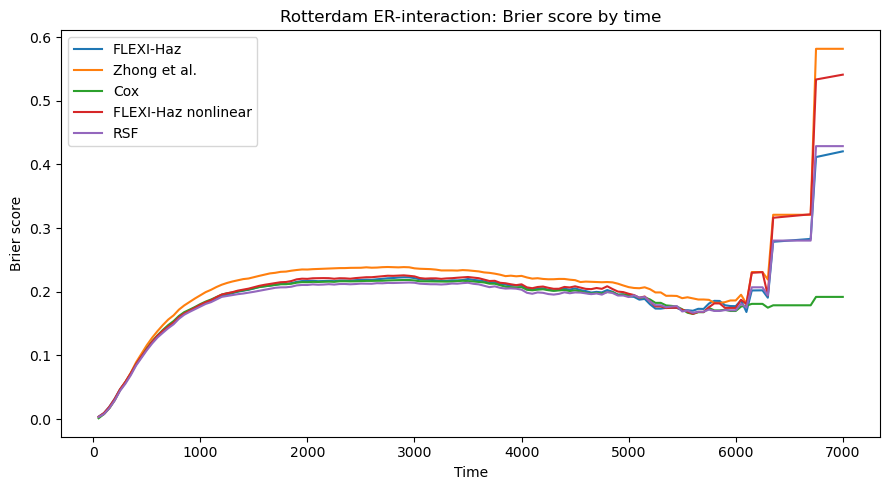

In [25]:
# Brier score curves using aggregated mean over folds.
if brier_by_time_summary.empty:
    display(Markdown("**No `brier_by_time_summary.csv` found.**"))
else:
    brier_plot = add_model_label(brier_by_time_summary)
    brier_plot = brier_plot.dropna(subset=["time", "brier_score_mean"])
    display(round_table(brier_plot.sort_values(["model_order", "time"]).head(20), 4))
    if not brier_plot.empty:
        plt.figure(figsize=(9, 5))
        for model in MODEL_ORDER:
            tmp = brier_plot[brier_plot["model"] == model].sort_values("time")
            if tmp.empty:
                continue
            plt.plot(tmp["time"], tmp["brier_score_mean"], label=MODEL_LABELS.get(model, model))
        plt.xlabel("Time")
        plt.ylabel("Brier score")
        plt.title("Rotterdam ER-interaction: Brier score by time")
        plt.legend()
        plt.tight_layout()
        plt.savefig(OUT_DIR / "brier_by_time.png", dpi=200)
        plt.show()


## Treatment effects summary

The slide-style ER-interaction table should use the log-HR scale:

```text
estimate_mean (ci95_low_mean, ci95_high_mean)
```

Do not use the hazard-ratio columns for the slide because the uploaded slide reports log-HR values and says: “Negative log-HR indicates lower hazard.”


In [26]:
if treatment_summary.empty:
    display(Markdown("**No `treatment_effects_summary.csv` found.** Treatment effects exist only for Cox, FLEXI-Haz partially linear, and Zhong."))
else:
    tx = treatment_summary.copy()
    tx = add_model_label(tx)
    tx["treatment"] = tx["parameter"].map(lambda x: TREATMENT_LABELS.get(x, (str(x), ""))[0])
    tx["ER"] = tx["parameter"].map(lambda x: TREATMENT_LABELS.get(x, ("", ""))[1])
    tx["significant_95"] = tx.apply(is_significant, axis=1)
    tx["slide_cell"] = tx.apply(ci_cell, axis=1)
    tx["treatment_order"] = tx["parameter"].map({p: i for i, p in enumerate(TREATMENT_ORDER)}).fillna(999).astype(int)

    cols = [
        "model_label", "parameter", "treatment", "ER",
        "estimate_mean", "estimate_std",
        "se_mean", "se_std",
        "ci95_low_mean", "ci95_high_mean",
        "hazard_ratio_mean", "hr_ci95_low_mean", "hr_ci95_high_mean",
        "p_value_mean", "significant_95", "slide_cell",
    ]
    cols = [c for c in cols if c in tx.columns]
    tx_display = tx.sort_values(["model_order", "treatment_order"])[cols]
    display(round_table(tx_display, 4))
    tx_display.to_csv(OUT_DIR / "treatment_effects_detailed_summary.csv", index=False)


,model_label,parameter,treatment,ER,estimate_mean,estimate_std,se_mean,se_std,ci95_low_mean,ci95_high_mean,hazard_ratio_mean,hr_ci95_low_mean,hr_ci95_high_mean,p_value_mean,significant_95,slide_cell
7,FLEXI-Haz,hormon_low_er,Hormonal,Low,-0.1899,0.0356,0.1545,0.0085,-0.4926,0.1129,0.8275,0.6115,1.1201,NaN,False,"-0.190 (-0.493, 0.113)"
6,FLEXI-Haz,hormon_high_er,Hormonal,High,-0.4957,0.1161,0.1472,0.0033,-0.7843,-0.2071,0.6124,0.4591,0.8169,NaN,True,"-0.496 (-0.784, -0.207)"
5,FLEXI-Haz,chemo_low_er,Chemo,Low,-0.3089,0.0599,0.1432,0.0071,-0.5895,-0.0283,0.7353,0.5553,0.9738,NaN,True,"-0.309 (-0.590, -0.028)"
4,FLEXI-Haz,chemo_high_er,Chemo,High,-0.3521,0.0761,0.1460,0.0073,-0.6384,-0.0659,0.7048,0.5291,0.9391,NaN,True,"-0.352 (-0.638, -0.066)"
11,Zhong et al.,hormon_low_er,Hormonal,Low,0.0930,0.3258,0.1401,0.0174,-0.1817,0.3676,1.1473,0.8644,1.5242,NaN,False,"0.093 (-0.182, 0.368)"
10,Zhong et al.,hormon_high_er,Hormonal,High,-0.1591,0.0931,0.1286,0.0036,-0.4111,0.0929,0.8558,0.6652,1.1011,NaN,False,"-0.159 (-0.411, 0.093)"
9,Zhong et al.,chemo_low_er,Chemo,Low,-0.0285,0.1723,0.0927,0.0030,-0.2101,0.1531,0.9839,0.8200,1.1807,NaN,False,"-0.029 (-0.210, 0.153)"
8,Zhong et al.,chemo_high_er,Chemo,High,-0.1318,0.1451,0.1140,0.0022,-0.3554,0.0917,0.8841,0.7072,1.1053,NaN,False,"-0.132 (-0.355, 0.092)"
3,Cox,hormon_low_er,Hormonal,Low,0.0832,NaN,0.1051,NaN,-0.1228,0.2892,1.0868,0.8844,1.3354,0.4286,False,"0.083 (-0.123, 0.289)"
2,Cox,hormon_high_er,Hormonal,High,-0.3063,NaN,0.1031,NaN,-0.5084,-0.1042,0.7362,0.6014,0.9010,0.0030,True,"-0.306 (-0.508, -0.104)"


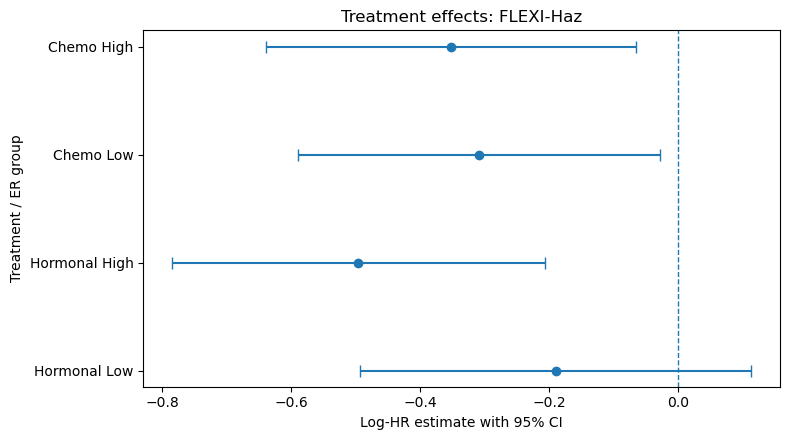

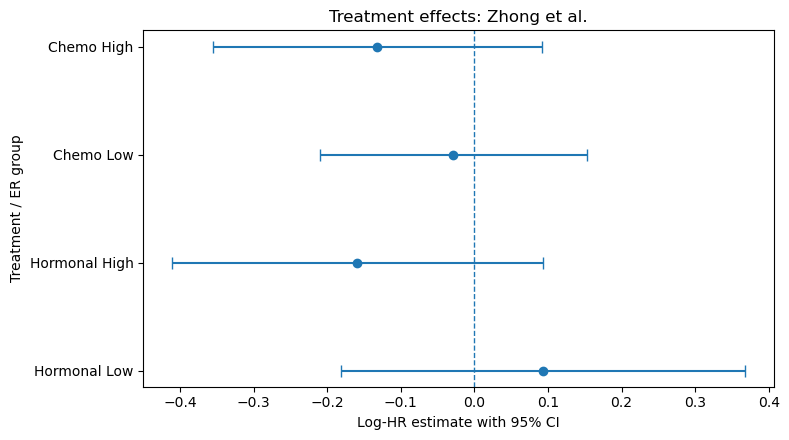

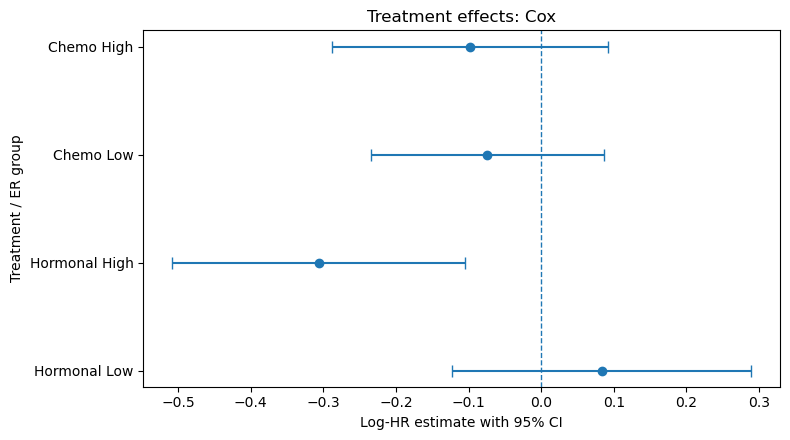

In [27]:
# Plot treatment estimates with 95% CI for models that provide direct beta coefficients.
if not treatment_summary.empty:
    tx_plot = treatment_summary.copy()
    tx_plot = add_model_label(tx_plot)
    tx_plot = tx_plot[tx_plot["parameter"].isin(TREATMENT_ORDER)].copy()
    tx_plot["treatment_er"] = tx_plot["parameter"].map(lambda x: f"{TREATMENT_LABELS[x][0]} {TREATMENT_LABELS[x][1]}")
    tx_plot["treatment_order"] = tx_plot["parameter"].map({p: i for i, p in enumerate(TREATMENT_ORDER)}).astype(int)
    tx_plot = tx_plot.sort_values(["model_order", "treatment_order"])

    for model in ["flexihaz_partial_linear", "zhong2022_ph", "cox_ph"]:
        tmp = tx_plot[tx_plot["model"] == model].dropna(subset=["estimate_mean", "ci95_low_mean", "ci95_high_mean"])
        if tmp.empty:
            continue
        y = np.arange(len(tmp))
        x = tmp["estimate_mean"].to_numpy(dtype=float)
        xerr = np.vstack([
            x - tmp["ci95_low_mean"].to_numpy(dtype=float),
            tmp["ci95_high_mean"].to_numpy(dtype=float) - x,
        ])
        plt.figure(figsize=(8, 4.5))
        plt.errorbar(x, y, xerr=xerr, fmt="o", capsize=4)
        plt.axvline(0.0, linestyle="--", linewidth=1)
        plt.yticks(y, tmp["treatment_er"])
        plt.xlabel("Log-HR estimate with 95% CI")
        plt.ylabel("Treatment / ER group")
        plt.title(f"Treatment effects: {MODEL_LABELS.get(model, model)}")
        plt.tight_layout()
        fname = f"treatment_effects_{model}.png"
        plt.savefig(OUT_DIR / fname, dpi=200)
        plt.show()


## Slide-style ER-interaction table

This reproduces the structure of the uploaded slide:

```text
Treatment | ER | FLEXI-Haz | Zhong et al. | Cox
```

Each cell is:

```text
estimate_mean (ci95_low_mean, ci95_high_mean)
```

The optional styled table highlights entries whose mean 95% CI excludes zero.


In [28]:
def make_slide_style_table(treatment_summary: pd.DataFrame) -> pd.DataFrame:
    if treatment_summary.empty:
        return pd.DataFrame()

    tx = treatment_summary.copy()
    tx = tx[tx["parameter"].isin(TREATMENT_ORDER)].copy()
    if tx.empty:
        return pd.DataFrame()

    tx["Treatment"] = tx["parameter"].map(lambda x: TREATMENT_LABELS[x][0])
    tx["ER"] = tx["parameter"].map(lambda x: TREATMENT_LABELS[x][1])
    tx["row_order"] = tx["parameter"].map({p: i for i, p in enumerate(TREATMENT_ORDER)})
    tx["cell"] = tx.apply(ci_cell, axis=1)
    tx["significant_95"] = tx.apply(is_significant, axis=1)

    wanted_models = ["flexihaz_partial_linear", "zhong2022_ph", "cox_ph"]
    model_cols = {
        "flexihaz_partial_linear": "FLEXI-Haz",
        "zhong2022_ph": "Zhong et al.",
        "cox_ph": "Cox",
    }

    rows = []
    for param in TREATMENT_ORDER:
        row_tx = tx[tx["parameter"] == param]
        if row_tx.empty:
            continue
        treatment, er = TREATMENT_LABELS[param]
        row = {"Treatment": treatment, "ER": er}
        for model in wanted_models:
            m = row_tx[row_tx["model"] == model]
            row[model_cols[model]] = "" if m.empty else m.iloc[0]["cell"]
        rows.append(row)

    return pd.DataFrame(rows, columns=["Treatment", "ER", "FLEXI-Haz", "Zhong et al.", "Cox"])

slide_table = make_slide_style_table(treatment_summary)
if slide_table.empty:
    display(Markdown("**Could not create slide-style table.** Check that treatment parameters are named `hormon_low_er`, `hormon_high_er`, `chemo_low_er`, `chemo_high_er`."))
else:
    display(slide_table)
    slide_table.to_csv(OUT_DIR / "slide_style_er_interaction_table.csv", index=False)


,Treatment,ER,FLEXI-Haz,Zhong et al.,Cox
0,Hormonal,Low,"-0.190 (-0.493, 0.113)","0.093 (-0.182, 0.368)","0.083 (-0.123, 0.289)"
1,Hormonal,High,"-0.496 (-0.784, -0.207)","-0.159 (-0.411, 0.093)","-0.306 (-0.508, -0.104)"
2,Chemo,Low,"-0.309 (-0.590, -0.028)","-0.029 (-0.210, 0.153)","-0.074 (-0.235, 0.086)"
3,Chemo,High,"-0.352 (-0.638, -0.066)","-0.132 (-0.355, 0.092)","-0.098 (-0.289, 0.093)"


In [29]:
# Optional styled version: significant entries are shown in red in Jupyter.
def style_significant_slide_table(slide_table: pd.DataFrame, treatment_summary: pd.DataFrame):
    if slide_table.empty or treatment_summary.empty:
        return slide_table

    sig_lookup = {}
    tx = treatment_summary[treatment_summary["parameter"].isin(TREATMENT_ORDER)].copy()
    for _, row in tx.iterrows():
        param = row["parameter"]
        model = row["model"]
        treatment, er = TREATMENT_LABELS[param]
        model_label = MODEL_LABELS.get(model, model)
        sig_lookup[(treatment, er, model_label)] = is_significant(row)

    def style_cell(value, row_idx=None, col_name=None):
        if col_name in ["Treatment", "ER"]:
            return ""
        treatment = slide_table.loc[row_idx, "Treatment"]
        er = slide_table.loc[row_idx, "ER"]
        if sig_lookup.get((treatment, er, col_name), False):
            return "color: red; font-weight: bold"
        return ""

    styles = pd.DataFrame("", index=slide_table.index, columns=slide_table.columns)
    for i in slide_table.index:
        for c in slide_table.columns:
            styles.loc[i, c] = style_cell(slide_table.loc[i, c], row_idx=i, col_name=c)
    return slide_table.style.apply(lambda _: styles, axis=None)

if not slide_table.empty:
    styled = style_significant_slide_table(slide_table, treatment_summary)
    display(styled)
    styled.to_html(OUT_DIR / "slide_style_er_interaction_table.html")


,Treatment,ER,FLEXI-Haz,Zhong et al.,Cox
0,Hormonal,Low,"-0.190 (-0.493, 0.113)","0.093 (-0.182, 0.368)","0.083 (-0.123, 0.289)"
1,Hormonal,High,"-0.496 (-0.784, -0.207)","-0.159 (-0.411, 0.093)","-0.306 (-0.508, -0.104)"
2,Chemo,Low,"-0.309 (-0.590, -0.028)","-0.029 (-0.210, 0.153)","-0.074 (-0.235, 0.086)"
3,Chemo,High,"-0.352 (-0.638, -0.066)","-0.132 (-0.355, 0.092)","-0.098 (-0.289, 0.093)"


## Full fold-level outputs

Use these tables to diagnose whether results are based on all 5 folds or only a smoke test.

If `estimate_std`, `se_std`, or metric standard deviations are missing/empty, check whether only one fold exists in the fold-level files.


In [30]:
if not summary_by_fold.empty:
    display(Markdown("### Fold-level predictive summary"))
    display(round_table(add_model_label(summary_by_fold).sort_values(["model_order", "fold"]), 4))

if not treatment_by_fold.empty:
    display(Markdown("### Fold-level treatment effects"))
    tx_fold = treatment_by_fold.copy()
    tx_fold = add_model_label(tx_fold)
    tx_fold["treatment"] = tx_fold["parameter"].map(lambda x: TREATMENT_LABELS.get(x, (str(x), ""))[0])
    tx_fold["ER"] = tx_fold["parameter"].map(lambda x: TREATMENT_LABELS.get(x, ("", ""))[1])
    display(round_table(tx_fold.sort_values(["model_order", "parameter", "fold"]), 4))


### Fold-level predictive summary

KeyError: 'fold'

## Files created by this notebook

The notebook saves the main analysis outputs into:

```text
results_er_interaction/analysis_outputs/
```

Main generated files:

```text
predictive_performance_summary.csv
treatment_effects_detailed_summary.csv
slide_style_er_interaction_table.csv
slide_style_er_interaction_table.html
ibs_by_model.png
mean_auc_by_model.png
c_index_by_model.png
auc_by_time.png
brier_by_time.png
treatment_effects_flexihaz_partial_linear.png
treatment_effects_zhong2022_ph.png
treatment_effects_cox_ph.png
```
